# Учебный проект 2_Исследование надежности заемщиков

## Оглавление

1. [Описание](#описание)
2. [Импорт библиотек Python](#импорт-библиотек-python)
3. [Загрузка данных](#загрузка-данных)
4. [Предобработка данных](#предобработка-данных)
5. [Исследовательский анализ данных](#исследовательский-анализ-данных)
6. [Общий вывод](#общий-вывод)

## Описание

На исследовании находятся данные, предоставленные `крупным коммерческим банком` - **статистика о платёжеспособности клиентов**.

---

**Задача**

Разобраться, влияет ли семейное положение и количество детей клиента на факт погашения кредита в срок.

---

**Описание данных**

* **children** - количество детей в семье;
* **days_employed** - общий трудовой стаж в днях;
* **dob_years** - возраст клиента в годах;
* **education** - уровень образования клиента;
* **education_id** - идентификатор уровня образования;
* **family_status** - семейное положение;
* **family_status_id** - идентификатор семейного положения;
* **gender** - пол клиента;
* **income_type** - тип занятости;
* **debt** - имел ли задолженность по возврату кредитов;
* **total_income** - ежемесячный доход;
* **purpose** - цель получения кредита.

## Импорт библиотек Python 

Данный этап характеризуется следующими последовательными действиями:

1. Импорт библиотек Python для работы над проектом в части:
  * работа с табличными данными:
    * numpy;
    * pandas.
  * визуализация данных:
    * matplotlib;
    * seaborn.
2. Инициализация констант для работы с проектом;
3. Формирование вывода по итогам данного этапа.

In [1]:
# импорт библиотек Python

## работа с табличными данными
## визуализация данных
import os
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
# инициализация переменных проекта

DIR_PATH = os.getcwd()
DATA_DIR = '../data/raw/'
DATA_NAME = 'data.csv'

# сборка пути к данным
DATA_PATH = os.path.join(DIR_PATH, DATA_DIR, DATA_NAME)

In [3]:
# установки настроек визуализации для всего проекта
plt.rcParams['figure.figsize'] = (12, 5)

**Вывод**

1. Импортированы библиотеки Python для работы над проектом в части:
  * работы с табличными данными:
    * numpy;
    * pandas.
  * визуализации данных:
    * matplotlib;
    * seaborn.
2. Инициализированы константы для работы с проектом:
  * **DIR_PATH** - текущая рабочая директория;
  * **DATA_DIR** - директория с хранимыми данными;
  * **DATA_NAME** - название исходного набора данных.

## Загрузка данных

Данный этап характеризуется следующими последовательными действиями:

1. Загрузка набора данных в рабочую среду Jupyter Notebook - инициализация переменной `data`;
2. Инициализация пользовательских функций предварительного обзора набора данных;
3. Вывод на экран основной информации о наборе данных для формирования плана последующих действий;
4. Формирование вывода по итогам данного этапа.

In [4]:
# загрузка данных в рабочую среду
data = pd.read_csv(DATA_PATH)

In [5]:
# инициализация пользовательской функции просмотра пропущенных значений
def na_statistics(df : pd.DataFrame) -> None:
    df_na = df.isna().sum().to_frame()
    df_na.columns = ['na_count']
    df_na['na_share'] = round(df_na['na_count'] / df.shape[0] * 100.0, 2)
    print('Пропущенные значения в наборе данных')
    display(df_na)

In [6]:
# инициализация пользовательской функции просмотра названий признаков и типов данных
def feature_info(df : pd.DataFrame) -> None:
    df_features = df.dtypes.to_frame()
    df_features.columns = ['feature_type']
    print('Названия признаков набора данных и их типы')
    display(df_features)

In [7]:
# инициализация пользовательской функции построения распределений количественных непрерывных показателей
def num_distribution(column : str, bins : int):
    plt.subplot(1, 2, 1)
    plt.xlabel(f'Значения признака \n{column}')
    plt.ylabel('Частота значений признака')
    plt.title(f'Гистограмма значений \n{column}', fontsize = 10)
    sns.histplot(data = data, x = data[column], bins = bins)
    plt.subplot(1, 2, 2)
    plt.xlabel(f'Значения признака \n{column}')
    plt.title(f'Диаграмма размаха значений \n{column}', fontsize = 10)
    sns.boxplot(data = data, x = data[column])
    plt.grid(False)
    plt.show()

In [8]:
# инициализация пользовательской функции построения распределений количественных дискретных показателей
def discr_distribution(column : str):
    ax = (
        sns.countplot(
            data = data,
            x = column,
            stat='count'
        )
    )

    ax.set(
        xlabel = f'Значения признака {column}',
        ylabel = 'Количество значений по признаку',
        title = f'Распределение значнений по признаку {column}'
    )
    plt.xticks(rotation = 45)
    plt.show()

In [9]:
# вывод на экран общей статистики по пропущенным значениям
na_statistics(data)

Пропущенные значения в наборе данных


,na_count,na_share
children,0,0.0
days_employed,2174,10.1
dob_years,0,0.0
education,0,0.0
education_id,0,0.0
family_status,0,0.0
family_status_id,0,0.0
gender,0,0.0
income_type,0,0.0
debt,0,0.0


In [10]:
# вывод на экран информации по признакам и их типам
feature_info(data)

Названия признаков набора данных и их типы


,feature_type
children,int64
days_employed,float64
dob_years,int64
education,object
education_id,int64
family_status,object
family_status_id,int64
gender,object
income_type,object
debt,int64


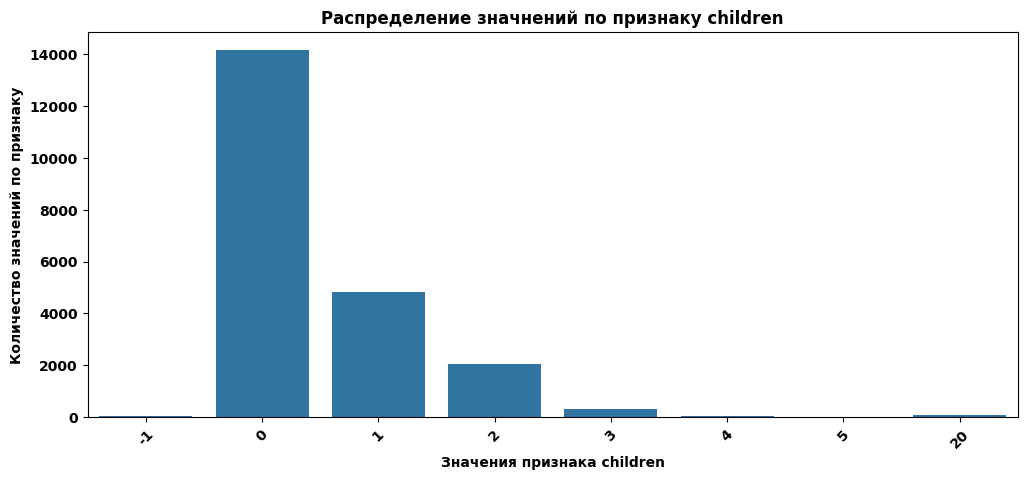

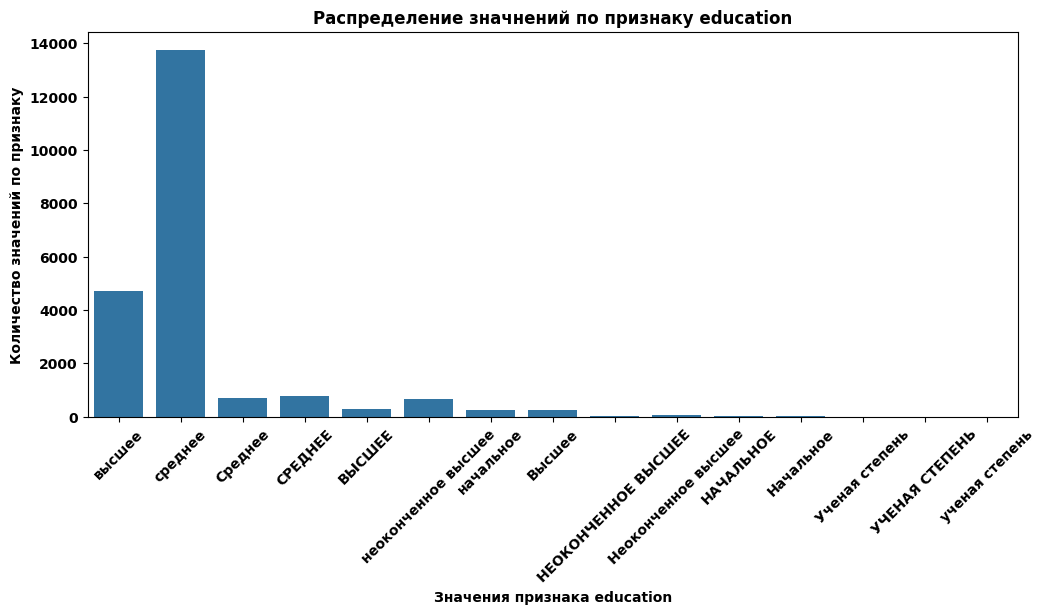

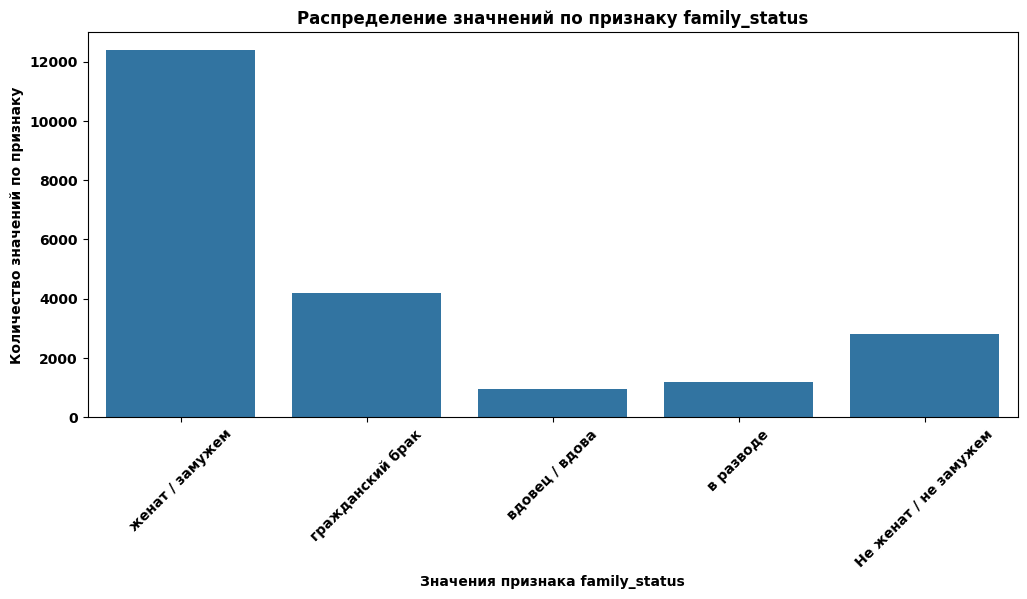

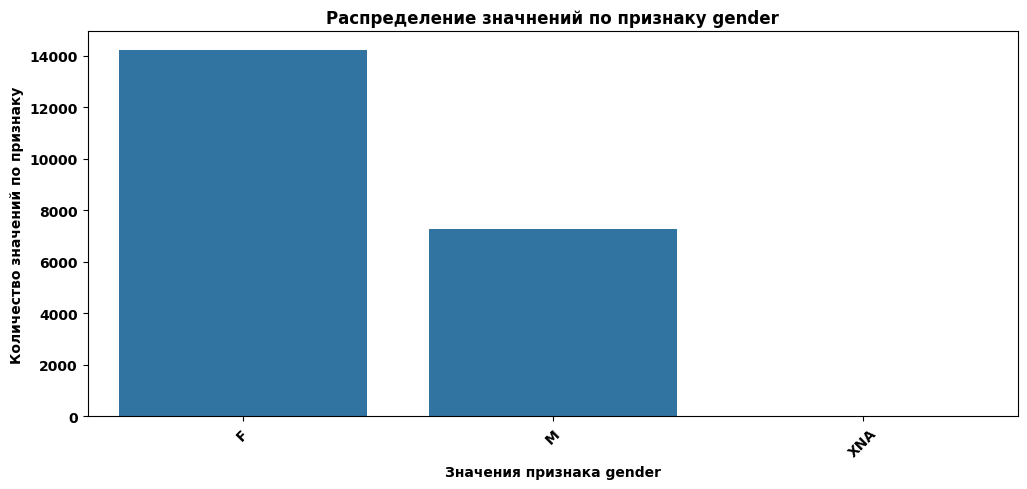

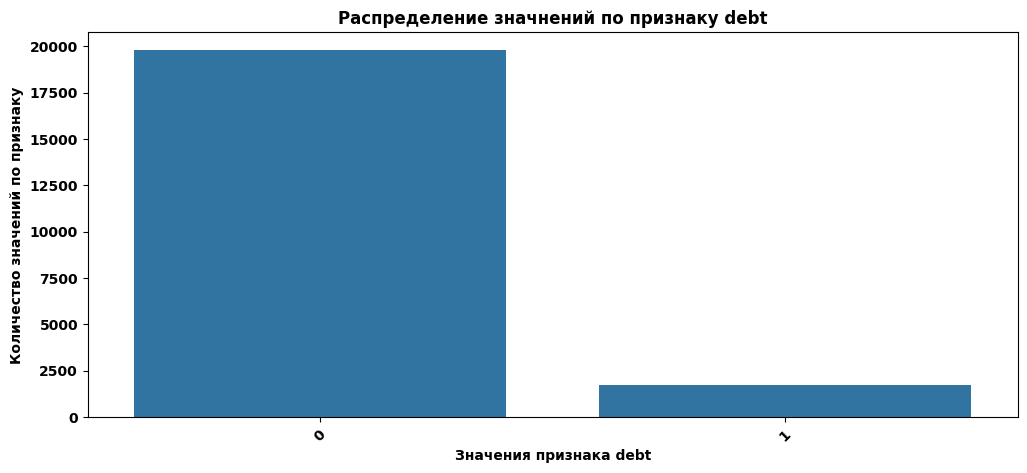

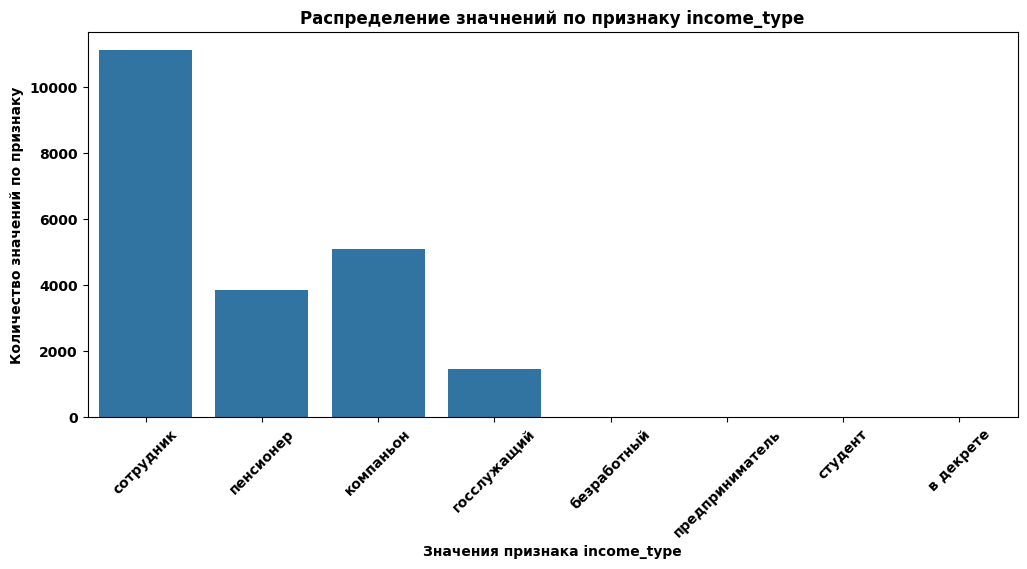

In [11]:
# построение визуализации дискретных количественных показателей
discr_features = ['children', 'education', 'family_status', 'gender', 'debt', 'income_type']

for feature in discr_features:
    discr_distribution(feature)

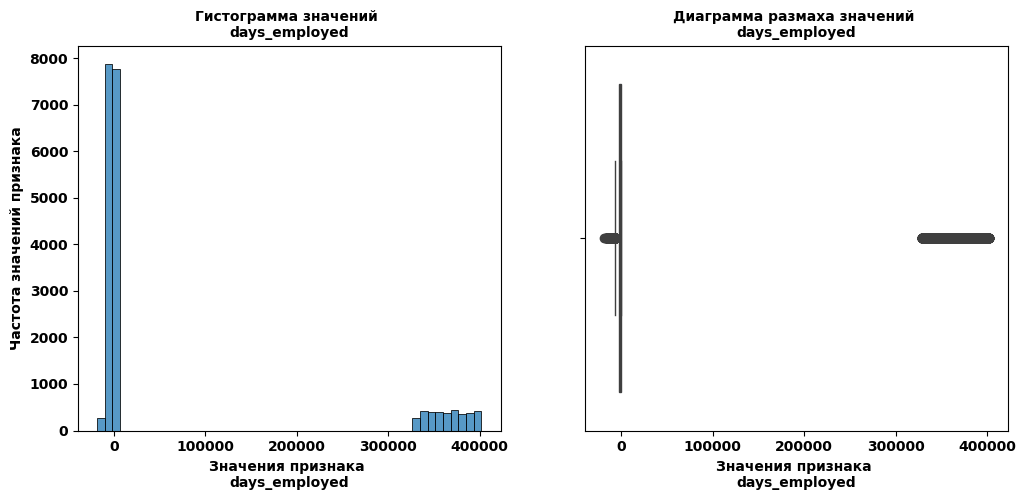

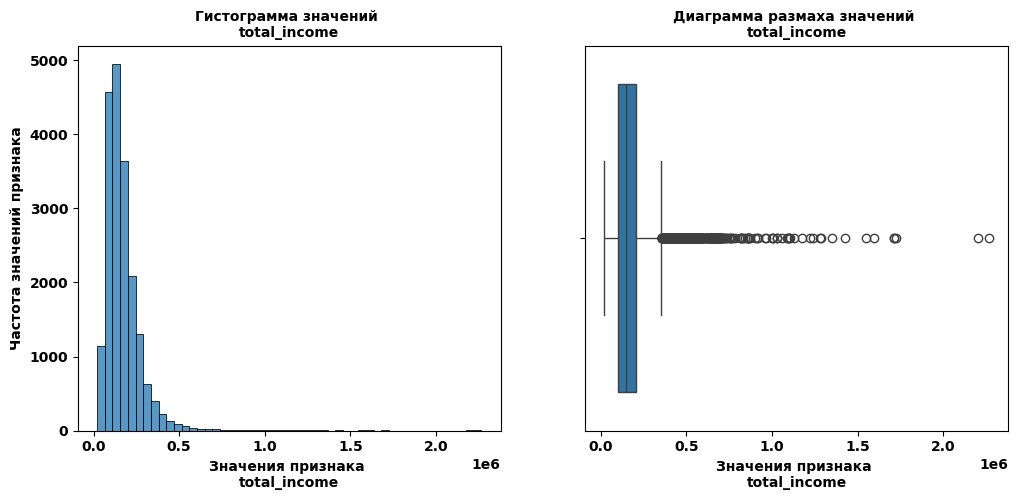

In [12]:
# построение визуализации непрерывных количественных показателей
num_features = ['days_employed', 'total_income']

for feature in num_features:
    num_distribution(feature, 50)

In [13]:
# вывод на экран информации о размере данных
print(f'Количество строк в наборе данных: {data.shape[0]}')
print(f'Количество столбцов в наборе данных: {data.shape[1]}')

Количество строк в наборе данных: 21525
Количество столбцов в наборе данных: 12


**Вывод**

1. Выполнена загрузка данных в рабочую среду - инициализирована переменная `data`;
2. Инициализированы пользовательские функции для просмотра первичной информации о наборе данных:
  * na_statistics - для просмотра пустых значений;
  * feature_info - для просмотра названий признаков набора данных и их типов;
  * num_distribution - для просмотра распределения количественных показателей (таких значений в наборе нет).
3. Выведена основная информация о наборе данных:
  * Количество строк - **21_525**, Количество столбцов - **12**;
  * Типы данных:
    * **children** - количество детей в семье - целочисленный;
    * **days_employed** - общий трудовой стаж в днях - число с плавающей точкой;
    * **dob_years** - возраст клиента в годах - целочисленный;
    * **education** - уровень образования клиента - строка;
    * **education_id** - идентификатор уровня образования - целочисленный;
    * **family_status** - семейное положение - строка;
    * **family_status_id** - идентификатор семейного положения - целочисленный;
    * **gender** - пол клиента - строка;
    * **income_type** - тип занятости - строка;
    * **debt** - имел ли задолженность по возврату кредитов - целочисленный;
    * **total_income** - ежемесячный доход - число с плавающей точкой;
    * **purpose** - цель получения кредита - строка.
  * **Нарушений форматирования snake_case** в названиях признаков не наблюдается;
  * **Имеются пропущенные значения по набору данных**:
    * **days_employed**;
    * **total_income**;
    * Также есть пустые значения в признаке **gender** (вероятно ошибка в типе данных);
  * **Обнаружены отрицательные значения по признакам**:
    * **children**;
    * **days_employed**.
  * **Обнаружены аномально большие значения по признакам**:
    * **days_employed**;
    * **total_income**.
  * **Обнаружены неявные дубликаты** по признаку **education**;
  * **Есть дублирование признаков по семантике**:
    * education и education_id;
    * family_status и family_status_id.

## Предобработка данных

Данный этап характеризуется следующими последовательными действиями:

1. Замена пропущенных значений по набору данных:
    * **total_income**;
    * **days_employed**;
    * **gender**.
2. Проверка набора данных на дубликаты (явные и неявные);
3. Проверка набора данных на аномальные значения и принятие решений об их устранении;
4. Преобразование типов данных с учетом семантики значений в столбце;
5. Формирование вывода по итогам данного этапа.

In [14]:
# пользовательская функция обработки строковых значений по набору данных
def string_preparation(column : pd.Series) -> pd.Series:
    return (
        column.str.strip()
        .str.lower()
        .str.replace(' ', '_')
    )

# обработка неявных дубликатов по категориальным строковым признакам
for col in ['education', 'family_status', 'income_type', 'purpose']:
    data[col] = string_preparation(data[col])

In [15]:
# проверка совпадения пропущенных значений по строкам для признаков 'total_income' и 'days_employed'
data[(data['total_income'].isna() == True) & (data['days_employed'].isna() == True)].shape[0]

2174

**Вывод по промежуточному этапу**

Обнаружено полное совпадение количества строк с пропущенными значениями по признакам **total_income** и **days_employed**

Вероятнее всего данная информация приведена по сотрудникам, которые только устроились на работу и у них не зафиксирован трудовой стаж и сумма доходов.

**Принятое решение**

Заполнить медианным значением приведенные показатели. Эта статистика - лучшее решение в данном случае.
Исключать 10% записей от исходного набора нельзя.

Заполнение произвести, опираясь на признак **income_type** - определенная профессиональная группа клиента. 

In [16]:
# заполнение пустых значений с учетом профессиональной группы клиента

# инициализация пользовательской функции заполнения значений в зависимости от группы
def fillna_by_group(df : pd.DataFrame, na_column : str, group_column : str, function : str) -> pd.Series:
    return (
        df[na_column].fillna(
            df.groupby(group_column)[na_column]
            .transform(function)
        )
    )

In [17]:
# заполнение пустот по группам
data['total_income'] = fillna_by_group(data, 'total_income', 'income_type', 'median')
data['days_employed'] = fillna_by_group(data, 'days_employed', 'income_type', 'median')

# проверка наличия пустот в наборе данных
na_statistics(data)

Пропущенные значения в наборе данных


,na_count,na_share
children,0,0.0
days_employed,0,0.0
dob_years,0,0.0
education,0,0.0
education_id,0,0.0
family_status,0,0.0
family_status_id,0,0.0
gender,0,0.0
income_type,0,0.0
debt,0,0.0


In [18]:
# преобразование значений в признаке 'gender'
gender_map = {
    'M' : 1,
    'F' : 0
}

# исключение из набора данных строки со значением XNA
data = data.loc[data['gender'].isin(['M', 'F'])].copy()

data['gender'] = (
    pd.to_numeric(
        data['gender'].replace(gender_map)
    ).astype(int)
)

C:\Users\k.storozhuk\AppData\Local\Temp\ipykernel_14452\3598805844.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data['gender'].replace(gender_map)


In [19]:
# проверка набора данных на наличие полных дубликатов
print(f'Количество полных дубликатов в наборе: {int(data.duplicated().sum())}')
print(f'Доля полных дубликатов в наборе: {float(data.duplicated().sum() / data.shape[0]):.2%}')

Количество полных дубликатов в наборе: 71
Доля полных дубликатов в наборе: 0.33%


In [20]:
# исключение полных дубликатов из набора данных
data = data.drop_duplicates().reset_index(drop=True)

In [21]:
# замена типов данных на соответствующие семантике значений
data['days_employed'] = data['days_employed'].astype(int)
data['total_income'] = data['total_income'].astype(int)

In [24]:
# проверка набора данных на аномальные значения

# проверка столбца 'children' на аномалии
print(f'Количество записей с отрицательными значениями: {(data["children"] < 0).sum()}')
print(f'Количество записей аномально большими значениями: {(data["children"] > 5).sum()}')

Количество записей с отрицательными значениями: 47
Количество записей аномально большими значениями: 76


**Вывод по промежуточному этапу**

На фоне общего количества записей в наборе данных подобное количество строк с аномальными значениями выглядит несущественным - **от них можно смело избавиться**.

Однако, можно выдвинуть гипотезу о том, что отрицательные значения по данному признаку появились в следствие технической ошибки (или человеческий фактор) внесения данных.

**Принятое решение**

Отрицательные значения преобразовать к положительным; Аномально большие - исключить.

In [25]:
# преобразование отрицательных значений признака 'children'
data['children'] = abs(data['children'])

# исключение из набора данных аномально больших значений по признаку 'children'
data = data.loc[data['children'] <= 5]

In [26]:
# проверка набора данных на аномальные значения

# проверка столбца 'days_employed' на аномалии
print(f'Количество записей с отрицательными значениями: {(data["days_employed"] < 0).sum()}')

Количество записей с отрицательными значениями: 17555


In [ ]:
# преобразование отрицательных значений признака 'days_employed'
data['days_employed'] = abs(data['days_employed'])

**Вывод по промежуточному этапу**

Признак **days_employed** на текущий момент также характеризуется аномально большими значениями. Сотни тысяч дней соответствуют сотням лет.
Вероятно, что сами значения имеют неверный формат записи - их могли внести в часах.

**Принятое решение**

Принимается верхняя граница трудового стажа россиянина до выхода на пенсию - 55 лет. Выше этой границы значения из набора данных исключаются.

In [28]:
# фильтрация набора данных по признаку 'days_employed' - исключение аномально больших значений из набора
data['days_employed'] = (
    np.where(
        data['days_employed'] > 55 * 365, data['days_employed'] / 24, data['days_employed']
    )
)

**Вывод**

1. Проведена замена пропущенных значений по набору данных:
    * **total_income** - заполнено медианным значением по группам;
    * **days_employed** - заполнено медианным значением по группам;
    * **gender** - исключено пропущенное значение.
2. Проверка набора данных на дубликаты (явные и неявные):
    * Полные явные дубликаты исключены из набора данных - удалены строки;
    * Неявные дубликаты прошли преобразование и исключены из набора - с сохранением строк.
3. Проверка набора данных на аномальные значения и принятие решений об их устранении:
    * **children** - отрицательные значения преобразованы к положительным; Исключены из набора данных аномально большие значения;
    * **days_employed** - отрицательные значения преобразованы к положительным; Исключены из набора данных аномально большие значения;
4. Преобразование типов данных с учетом семантики значений в столбце:
    * **total_income** - целочисленный тип данных;
    * **days_employed** - целочисленный тип данных;
    * **gender** - целочисленный тип данных

## Исследовательский анализ данных

### Шаг 2.5. Формирование дополнительных датафреймов словарей, декомпозиция исходного датафрейма.

Создайте два новых датафрейма со столбцами:
- 'education_id' и 'education' — в первом;
- 'family_status_id' и 'family_status' — во втором.

In [ ]:
# Скопируем исходный датафрейм и присвоим это значение новой переменной, которая будет содержать в себе столбцы 'education' и
# 'education_id'
data_education = df.copy(deep=True)
data_education = data_education[['education','education_id']]
display(data_education)

In [ ]:
# Проделаем ту же самую операцию для датафрейма, который будет содержать данные о семье. Скопируем исходный датафрейм и присвоим
# это значение новой переменной, которая будет содержать в себе столбцы 'education' и 'education_id'
data_family = df.copy(deep=True)
data_family = data_family[['family_status','family_status_id']]
display(data_family)

Теперь удалим в исходном датафрейме столбцы 'education' и 'family_status'

In [ ]:
df.drop(columns = ['education', 'family_status'], axis = 1)
display(df.head())

<div class="alert alert-success">
<b>✔️ Комментарий ревьюера v1:</b> 
<br>Тут всё правильно 👌
</div>

### Шаг 2.6. Категоризация дохода.

На основании диапазонов из столбца 'total_income' создадим столбец 'total_income_category':

In [ ]:
total_income_category = []
for i in df['total_income']:
    if i <= 30000:
        total_income_category.append('E')
    elif i <= 50000:
        total_income_category.append('D')
    elif i <= 200000:
        total_income_category.append('C')
    elif i <= 1000000:
        total_income_category.append('B')
    else:
        total_income_category.append('A')
df['total_income_category'] = total_income_category

In [ ]:
# проверим выполнение цикла путем вывода на экран 5 первых значений
display(df.head())

<div class="alert alert-success">
<b>✔️ Комментарий ревьюера v1:</b> 
<br>Категоризация клиентов по уровню дохода произведена верно
</div>

### Шаг 2.7. Категоризация целей кредита.

На основании данных из столбца purpose необходимо сформировать новый столбец 'purpose_category', в который войдут цели, ради которых берется кредит.

Для начала посмотрим уникальные значения в столбце 'purpose':

In [ ]:
df['purpose'].value_counts()

В каждой из целей есть ключевые слова, которые будут выполнять для нас роль критерия для категоризации целей кредита. Ключевые слова следующие:
- "свадьба";
- "недвижимость";
- "жилье";
- "автомобиль";
- "образование";

При категоризации необходимо особое внимание уделить окончаниям - использовать ключевые слова без них. Так же "жилье" и "недвижимость" будут сгруппированы в одну категорию - "операции с недвижимостью".

In [ ]:
# Создадим функцию, которая на основании данных из столбца purpose сформирует новый столбец purpose_category
def purpose_category(purpose):
    if 'свадьб' in purpose:
        return 'проведение свадьбы'
    elif 'автомобил' in purpose:
        return 'операции с автомобилем'
    elif 'образован' in purpose:
        return 'получение образования'
    return 'операции с недвижимостью'

In [ ]:
# применим написанную функцию для создания нового столбца
df['purpose_category'] = df['purpose'].apply(purpose_category)

In [ ]:
display(df.head())

<div class="alert alert-success">
<b>✔️ Комментарий ревьюера v1:</b> 
<br>Основные цели кредита определены правильно! 👍
</div>

### Ответы на вопросы.

##### Есть ли зависимость между количеством детей и возвратом кредита в срок?:

In [ ]:
# Выделим колонки с данными о детях и задолженностях у клиентов в отдельный датафрейм
df_pivot_children = df.pivot_table(index='gender', columns='children', values='debt', aggfunc='sum')
display(df_pivot_children)

Напишем функцию которая принимает список столбцов (или 1 столбец) для анализа просрочки и выводит таблицу с колонками: принятые столбцы / а) кол-во невыплат / б) кол-во записей в категории / доля невыплат по категории - а) делим на б)

In [ ]:
def analyse_debt(column_list):
    analyse_table = df.groupby(column_list).agg({'debt':['sum', 'count']})
    analyse_table[('debt', 'part/cat,%')] = analyse_table[('debt', 'sum')] / analyse_table[('debt', 'count')]*100
    return analyse_table

display(analyse_debt(['children']))

**Вывод**: Стоит отметить следующий факт - наличие детей влияет на задолженность человека по кредиту. Можно увидеть, как процент невозврата кредита у бездетных клиентов резко возрастает у клиентов с одним ребенком. Стоит так же заметить, что большой разницы невозврата кредита, исходя из количества детей, нету, но при этом снижается у клиентов с 3 детьми. Можно предположить, что большую роль здесь играют меры государственной поддержки многодетных семей.

<div class="alert alert-success">
<b>✔️ Комментарий ревьюера v1:</b> 
<br>Верно! 
</div>

##### Есть ли зависимость между семейным положением и возвратом кредита в срок?

Создадим сводную таблицу 'df_pivot_family_status', чтобы проанализировать количество должников в зависимости от их семейного статуса

In [ ]:
df_pivot_family_status = df.groupby(['family_status_id', 'family_status']).agg({'debt':['sum', 'count']})

df_pivot_family_status[('debt', 'part,%')] = df_pivot_family_status[('debt', 'sum')] / df_pivot_family_status[('debt', 'count')]*100
display(df_pivot_family_status)

**Вывод**: Результат исследования показывает, что в группе клиентов со статусом не женат / не замужем доля должников больше всего - почти 9,8%. Меньше всего должников среди вдовцов - 6,6%

<div class="alert alert-success">
<b>✔️ Комментарий ревьюера v1:</b> 
<br>Согласен! Идём дальше)
</div>

##### Есть ли зависимость между уровнем дохода и возвратом кредита в срок?

Создадим функцию для категоризации уровней дохода клиентов

<div class="alert alert-danger">
<b>❌ Комментарий ревьюера v2:</b> 
<br>Ты раньше уже провёл категоризацию, её не нужно делать ещё раз. Удали эту часть кода и сделать расчет внутри групп столбца total_income_category
</div>

<div class="alert alert-info">
<b>Комментарий студента:</b>
<br>Извиняюсь за повторенную ошибку - подумал, что необходимо придерживаться буквенной классификации и просто заменил категории на буквы, хотя делал это выше. Так же понял, почему возникала ошибка, описанная пунктами ниже: я категоризовал уже сгруппированные ранее значения 
</div>

<div class="alert alert-success">
<b>✔️ Комментарий ревьюера v3:</b>
<br>Отлично! Расчеты верные, но ты немного запутался в буквах) Самая большая доля должников в группе E
</div>

Применим созданную функцию и сгруппируем значения по категориям дохода

In [ ]:
df_pivot_debtors_income = df.groupby(['total_income_category']).agg({'debt':['sum', 'count']})
df_pivot_debtors_income[('debt', 'part,%')] = df_pivot_debtors_income[('debt', 'sum')] / df_pivot_debtors_income[('debt', 'count')]*100
display(df_pivot_debtors_income)

**Вывод**: После исправления кода для расчет количества должников картина поменялась. Сейчас больше всего должников в группе "D", которой обозначаются клиенты с уровнем дохода менее 30 000 у.е. - их 9% за счет немногочисленности самой группы "D". Следом идут должники в группе "С", куда определены клиенты с уровнем дохода от 50 000 до 200 000 у.е. - 8,48% от общего числа группы. Таким образом, нельзя установить корреляцию между уровнем дохода и возвратом кредита в срок

<div class="alert alert-danger">
<b>❌ Комментарий ревьюера v1:</b> 
<br>Используя категоризацию "A-B-C-D-E", которую ты сделал ранее и расчитай долю должников внутри каждой группы как ты это сделал для вопросов выше
</div>

<div class="alert alert-info">
<b>Комментарий студента:</b>
<br>Посчитал долю, как в предыдущих пунктах, но при исполнении кода появляется ошибка, в выводе которой содержится "Try using .loc[row_indexer,col_indexer] = value instead". Кай ее обойти, понять не могу
</div>

<div class="alert alert-warning">
<b>⚠️ Комментарий ревьюера v2:</b> 
<br>Чтобы избавиться от вывода предупреждений, нужно добавить две строчки
    
    import warnings
    warnings.simplefilter("ignore")
</div>

##### Как разные цели кредита влияют на его возврат в срок?

In [ ]:
display(analyse_debt(['purpose_category']))

**Вывод**: Количество должников больше всего среди клиентов, которые берут кредит на операции с недвижимостью, так как люди вынуждены обращаться за кредитом, чтобы купить себе жилье по нынешним ценам. Меньше же всего должников среди, клиентов, которые берут кредит на проведение свадьбы - видимо, люди стараются обойтись собственными накоплениями для организации торжества.

<div class="alert alert-danger">
<b>❌ Комментарий ревьюера v1:</b> 
<br>Тут нужно тоже расчитать долю должников. В этом может помочь aggfunc='mean'
</div>

<div class="alert alert-info">
<b>Комментарий студента:</b>
<br>Посчитал долю, применив написанную раннее функцию
</div>

<div class="alert alert-success">
<b>✔️ Комментарий ревьюера v2:</b>
<br>Отлично! Теперь всё верно)
</div>

## Общий вывод:

В ходе работы искали зависимость между:

1. наличием детей и возвратом кредита в срок - должников с детьми оказалось больше, чем бездетных, вне зависимости от их количества. Следовательно, наличие детей негативно влияет на возврат кредита в срок;

2. семейным положением и возвратом кредита в срок - зависимость есть, чаще всего становятся должниками люди с семейным положением "не женат/не замужем";

3. уровнем дохода и возвратом кредита в срок - выраженная зависимость между уровнем дохода и возвратом кредита в срок не установлена;

4. целью кредита и возвратом кредита в срок - зависимость есть, бОльшая доля должников взяла кредит на операции с недвижимостью и покупку автомобиля.

5. **Таким образом, формируется портрет клиента с максимальной вероятностью просрочки: а) имеет детей - в частности, клиенты с 4 детьми имеют самый высокий процент должников среди всей выборки; б) не женат/не замужем; в) берет кредит на операции с недвижимостью или на покупку автомобиля**

<div class="alert alert-danger">
<b>❌ Комментарий ревьюера v1:</b> 
<br>Добавь в общий вывод описание клиента с наибольшей вероятностью просрочки, например, женат, 3е детей, доход - такой-то, цель кредита - такая-то. Для этого используй ответы на вопросы выше
</div>

<div class="alert alert-danger">
<b>❌ Комментарий ревьюера v2:</b> 
<br>Чтобы сформировать портрет клиента с наибольшей вероятностью просрочки, посмотри ответ на каждый вопрос и посмотри внутри какой группы самая большая должников. Ты пишешь, что бездетные клиенты совершают просрочки чаще остальных, но это не так, ведь доля должников внутри этой группы самая низкая, но да, при этом их больше всех от общего числа клиентов
</div>

<div class="alert alert-info">
<b>Комментарий студента:</b>
<br>Написал про бездетность, потому что статус "не женат/не замужем" противоречит статусу "имеет 3 детей"))
</div>

<div class="alert alert-success">
<b>✔️ Комментарий ревьюера v3:</b>
<br>Всё верно, кроме пункта "в". Доля должников с целью взятия кредита на операции с недвижимость самая низкая
</div>

<div class="alert alert-danger">
<b>❌ Итоговый комментарий ревьюера v1:</b> 
<br>Ты хорошо потрудился, большая часть работы сделана, но остаётся внести следующие правки:
<br>- расчитать долю должников для 3-4 вопроса
<br>- поправить ответы на итоговые вопросы, если это будет необходимо
<br>- построить сводную таблицу используя метод pivot_table() для любого из вопросов в шаге 3. В таблице нужно произвести расчет доли должников внутри каждой группы клиентов. Это необходимо для отработки пройденного материала
<br>- дописать  общий вывод
</div>

<div class="alert alert-info">
<b>Комментарий студента:</b>
<br>Правка ответов на итоговые вопросы не потребовалась, так как полученные резальтаты в ходе вычислений не изменились
</div>

<div class="alert alert-danger">
<b>❌ Итоговый комментарий ревьюера v2:</b> 
<br>Ты хорошо потрудился, большая часть работы сделана, но остаётся внести следующие правки:
<br>- расчитать долю должников для 3 с учетом изначальной категоризации вопроса
<br>- поправить ответ на третий вопрос
<br>- поправить общий вывод
</div>